# Lab 4: Regression Analysis with Regularization Techniques
**Name:** Minh Le  
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50), Fall 2026  
**Dataset:** scikit-learn Diabetes

This lab compares simple, multiple, and polynomial regression with Ridge and Lasso.
The goal is to measure predictive accuracy and examine the tradeoff between model
complexity and generalization. All reported results below are produced by running this notebook.

## Step 1: Data preparation and exploration
The data contain 442 observations and 10 baseline measurements. The target is a
quantitative measure of disease progression one year after baseline. Features are
age, sex, BMI, average blood pressure (`bp`), and six serum measurements (`s1`–`s6`).
We load unscaled values so scaling can be learned from training data inside each pipeline.
The sex feature is a coded category, not a continuous physiological measurement.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Surface convergence problems instead of silently accepting unreliable fits.
warnings.filterwarnings('error', category=ConvergenceWarning)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12})
OUT = Path('results')
OUT.mkdir(exist_ok=True)
data = load_diabetes(as_frame=True, scaled=False)
X, y = data.data.copy(), data.target.copy()
frame = X.assign(target=y)
print(f'Observations: {len(X)}; predictors: {X.shape[1]}')
display(frame.head())
display(frame.describe().T.round(2))
display(pd.DataFrame({'dtype': frame.dtypes.astype(str), 'missing': frame.isna().sum()}))
print('Duplicate full rows:', frame.duplicated().sum())
assert not frame.isna().any().any(), 'Missing values require a training-fitted imputer.'
assert np.isfinite(frame.to_numpy()).all(), 'Nonfinite values require investigation.'
# No rows are removed: the built-in dataset is complete and numerical.

Observations: 442; predictors: 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


,dtype,missing
age,float64,0
sex,float64,0
bmi,float64,0
bp,float64,0
s1,float64,0
s2,float64,0
s3,float64,0
s4,float64,0
s5,float64,0
s6,float64,0


Duplicate full rows: 0


Training rows: 353; test rows: 89


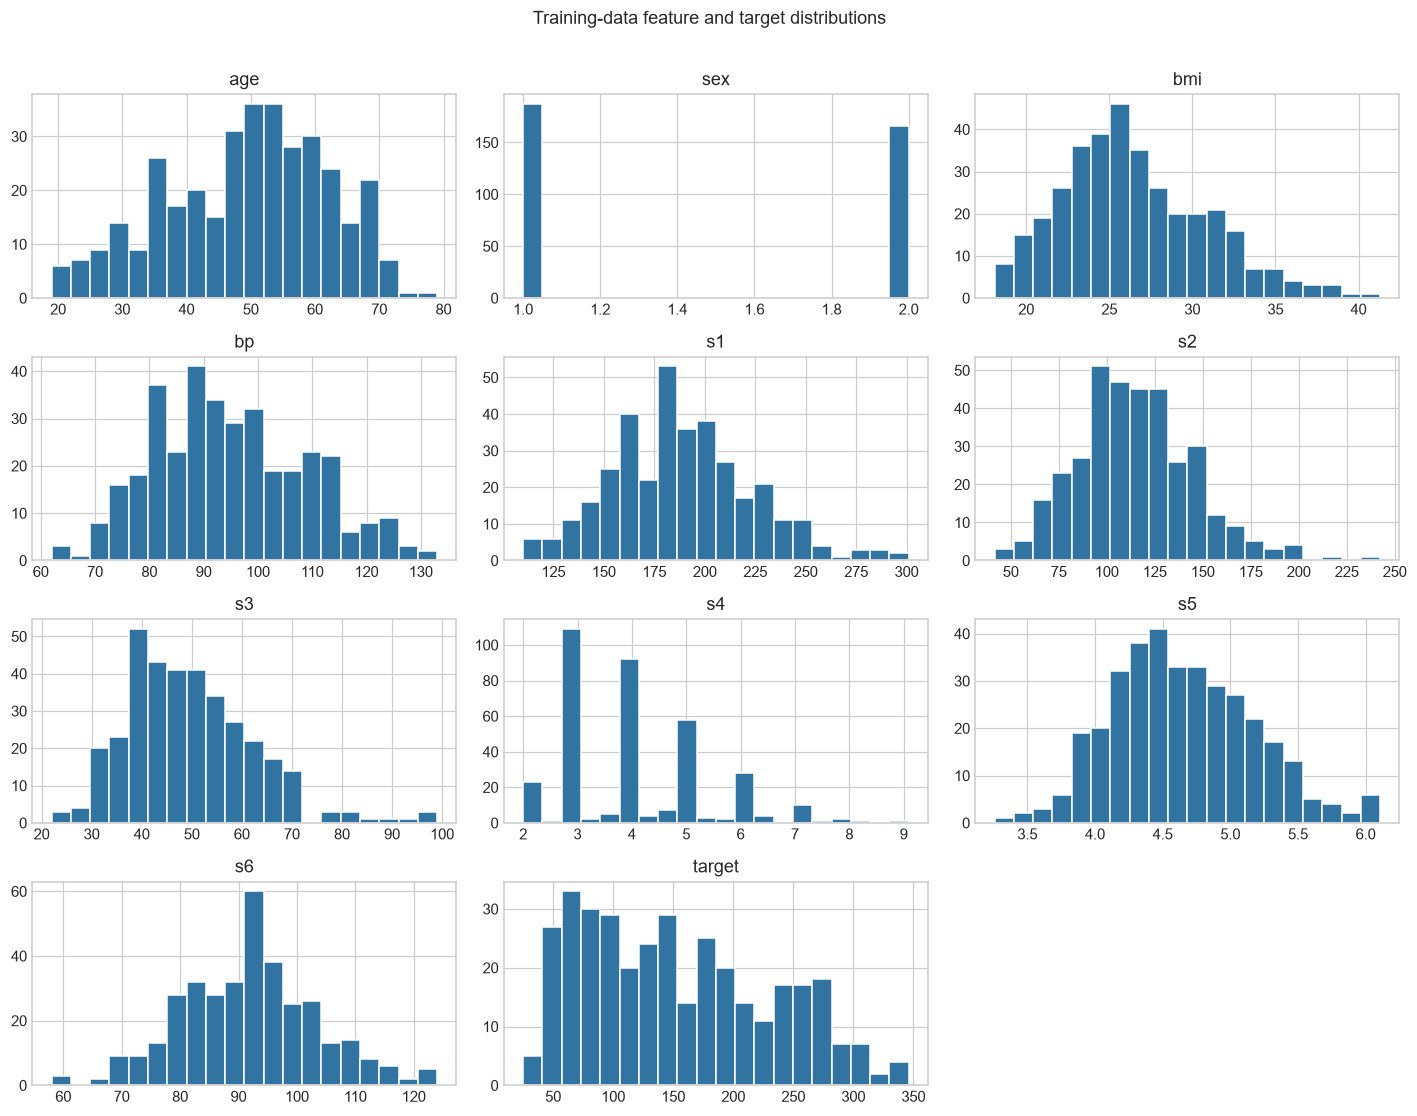

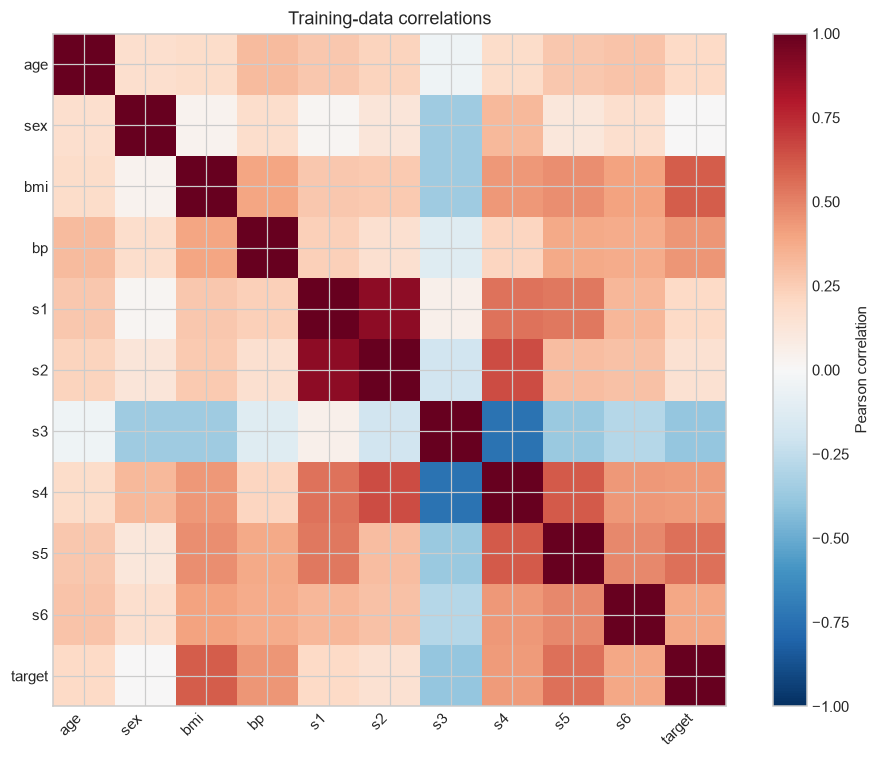

,Target correlation
bmi,0.605
s5,0.552
bp,0.445
s4,0.425
s6,0.390
s1,0.200
age,0.197
s2,0.155
sex,0.007
s3,-0.384


In [2]:
# Split once; all models use the same held-out observations.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print(f'Training rows: {len(X_train)}; test rows: {len(X_test)}')

# Examine training distributions to avoid using test patterns for model choices.
train_frame = X_train.assign(target=y_train)
train_frame.hist(bins=20, figsize=(13, 10), color='#3274A1', edgecolor='white')
plt.suptitle('Training-data feature and target distributions', y=1.01)
plt.tight_layout()
plt.savefig(OUT / 'distributions.png', bbox_inches='tight')
plt.show()
corr = train_frame.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Training-data correlations')
plt.tight_layout()
plt.savefig(OUT / 'correlations.png', bbox_inches='tight')
plt.show()
display(corr['target'].drop('target').sort_values(ascending=False).to_frame('Target correlation').round(3))

### Evaluation design
The 80/20 split uses seed 42. Hyperparameters are chosen by five-fold training-only
cross-validation (CV), minimizing mean fold RMSE. Scaling is fitted separately inside
each CV fold. Test scores are used only for the final comparison, not for tuning.

MAE is the mean absolute error; MSE is the mean squared error; RMSE is its square root.
Lower values are better. MAE and RMSE use target units, while MSE uses squared units.
R² measures improvement over predicting the evaluation set's mean: 1 is perfect,
0 matches that reference, and negative values are possible. A separate training-mean
dummy model provides a practical baseline. These are predictive associations, not causal effects.

In [3]:
models, rows, predictions = {}, [], {}
def evaluate(name, model, columns=None, cv_rmse=None):
    # Reuse identical rows, even when the simple model uses only BMI.
    columns = list(X.columns) if columns is None else columns
    model.fit(X_train[columns], y_train)
    train_pred = model.predict(X_train[columns])
    pred = model.predict(X_test[columns])
    models[name] = model
    predictions[name] = pred
    row = {'Model': name, 'MAE': mean_absolute_error(y_test, pred),
           'MSE': mean_squared_error(y_test, pred),
           'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
           'R2': r2_score(y_test, pred),
           'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
           'CV RMSE': cv_rmse}
    rows.append(row)
    return pd.DataFrame([row]).set_index('Model').round(3)

def actual_plot(ax, name):
    pred = predictions[name]
    ax.scatter(y_test, pred, alpha=0.7, s=24)
    limits = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(limits, limits, '--', color='black', label='Perfect prediction')
    ax.set(xlabel='Actual progression', ylabel='Predicted progression', title=name)
    ax.legend(fontsize=8)

display(evaluate('Mean baseline', DummyRegressor(strategy='mean')))

,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Mean baseline,64.006,5361.533,73.222,-0.012,77.951,None


## Step 2: Simple linear regression
BMI is chosen in advance as an interpretable single predictor. This model fits
`progression = intercept + slope × BMI`. It cannot represent information from the
other health measurements, so it may underfit compared with multiple regression.

,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Simple linear (BMI),52.26,4061.826,63.732,0.233,62.082,62.5


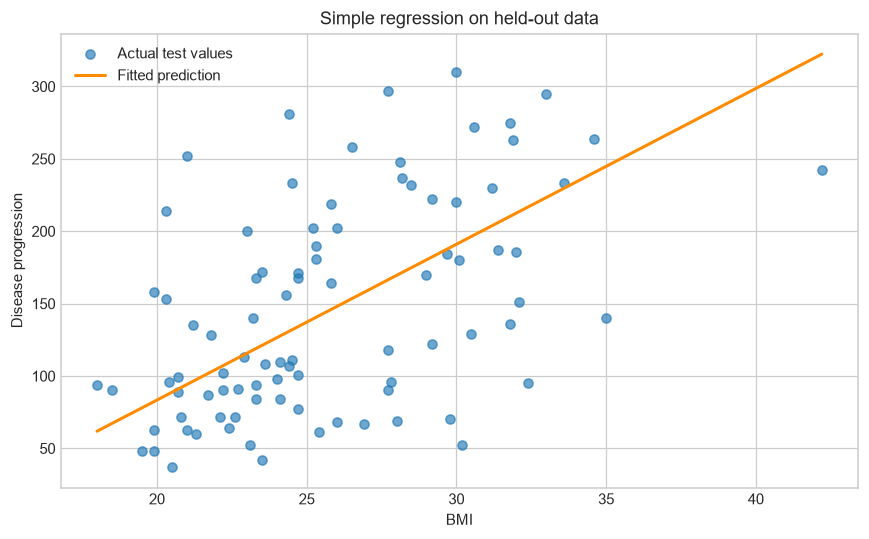

In [4]:
simple = Pipeline([('scale', StandardScaler()), ('reg', LinearRegression())])
simple_cv = -cross_val_score(simple, X_train[['bmi']], y_train, cv=cv,
                             scoring='neg_root_mean_squared_error').mean()
display(evaluate('Simple linear (BMI)', simple, ['bmi'], simple_cv))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_test['bmi'], y_test, alpha=0.65, label='Actual test values')
order = np.argsort(X_test['bmi'].to_numpy())  # Sort x-values to draw a continuous line.
ax.plot(X_test['bmi'].iloc[order], predictions['Simple linear (BMI)'][order],
        color='darkorange', linewidth=2, label='Fitted prediction')
ax.set(xlabel='BMI', ylabel='Disease progression', title='Simple regression on held-out data')
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'simple_regression.png')
plt.show()

## Step 3: Multiple regression
Multiple regression uses all 10 predictors and fits their additive linear effects.
Predictor correlations can make individual coefficients unstable even when predictions
are useful. Standardization puts coefficients on comparable feature scales.

,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Multiple linear,42.794,2900.194,53.853,0.453,53.559,55.395


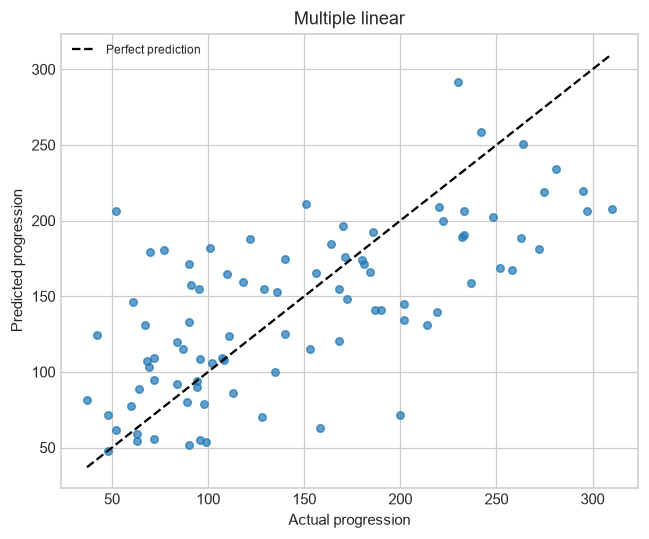

In [5]:
multiple = Pipeline([('scale', StandardScaler()), ('reg', LinearRegression())])
multiple_cv = -cross_val_score(multiple, X_train, y_train, cv=cv,
                               scoring='neg_root_mean_squared_error').mean()
display(evaluate('Multiple linear', multiple, cv_rmse=multiple_cv))
fig, ax = plt.subplots(figsize=(6, 5))
actual_plot(ax, 'Multiple linear')
plt.tight_layout()
plt.savefig(OUT / 'multiple_regression.png')
plt.show()

## Step 4: Polynomial regression and model complexity
Polynomial expansion includes powers and interactions of all 10 predictors. Degrees
1, 2, and 3 produce 10, 65, and 285 columns, respectively (excluding the intercept).
Degree 1 is the multiple linear model. We scale before expansion for numerical stability
and afterward so regularization will treat the expanded terms comparably.
Powers of the binary-coded sex feature are redundant; ordinary least squares handles
rank deficiency, but this is another reason not to interpret every expanded coefficient.

,Features,Train RMSE,CV RMSE,CV SD
Degree,,,,
1,10,53.559,55.395,2.361
2,65,48.920,62.505,4.412
3,285,27.379,1394.877,705.760


Degree preferred by training CV: 1


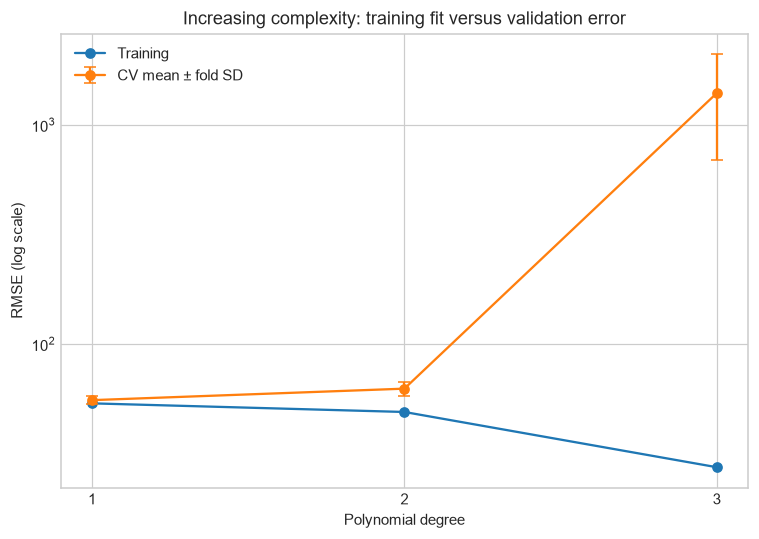

In [6]:
def polynomial_pipeline(degree, reg):
    return Pipeline([('input_scale', StandardScaler()),
                     ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                     ('scale', StandardScaler()), ('reg', reg)])

degree_rows = []
for degree in [1, 2, 3]:
    model = polynomial_pipeline(degree, LinearRegression())
    fold_rmse = -cross_val_score(model, X_train, y_train, cv=cv,
                                 scoring='neg_root_mean_squared_error')
    model.fit(X_train, y_train)
    degree_rows.append({'Degree': degree,
                       'Features': model.named_steps['poly'].n_output_features_,
                       'Train RMSE': np.sqrt(mean_squared_error(y_train, model.predict(X_train))),
                       'CV RMSE': fold_rmse.mean(), 'CV SD': fold_rmse.std()})
    if degree > 1:
        evaluate(f'Polynomial degree {degree}', model, cv_rmse=fold_rmse.mean())
degree_results = pd.DataFrame(degree_rows).set_index('Degree')
display(degree_results.round(3))
print('Degree preferred by training CV:', degree_results['CV RMSE'].idxmin())
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(degree_results.index, degree_results['Train RMSE'], 'o-', label='Training')
ax.errorbar(degree_results.index, degree_results['CV RMSE'], yerr=degree_results['CV SD'],
            fmt='o-', capsize=4, label='CV mean ± fold SD')
ax.set(xlabel='Polynomial degree', ylabel='RMSE (log scale)', yscale='log',
       title='Increasing complexity: training fit versus validation error', xticks=[1, 2, 3])
ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'polynomial_complexity.png')
plt.show()

## Step 5: Ridge and Lasso regularization
Ridge adds an L2 penalty (squared coefficients); Lasso adds an L1 penalty (absolute
coefficients). Increasing alpha encourages smaller coefficients and can reduce variance;
excessive alpha causes underfitting. Lasso can set coefficients to zero, whereas Ridge
typically retains them. The intercept is not penalized. scikit-learn normalizes the loss
differently for Ridge and Lasso, so the same numeric alpha does not mean equal strength.

We tune both methods on the original 10 predictors and on the degree-2 expansion.
The extra polynomial fits test whether regularization improves an overly flexible model.
All alpha grids and degree choices are specified before inspecting test performance.

,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Ridge,42.812,2892.015,53.777,0.454,53.575,55.374


Ridge: selected alpha = 1


,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Lasso,42.815,2882.154,53.686,0.456,53.611,55.349


Lasso: selected alpha = 0.14678


,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Ridge polynomial degree 2,41.471,2649.612,51.474,0.5,51.65,56.87


Ridge polynomial degree 2: selected alpha = 100


,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Lasso polynomial degree 2,41.269,2569.712,50.692,0.515,53.504,55.958


Lasso polynomial degree 2: selected alpha = 3.1623


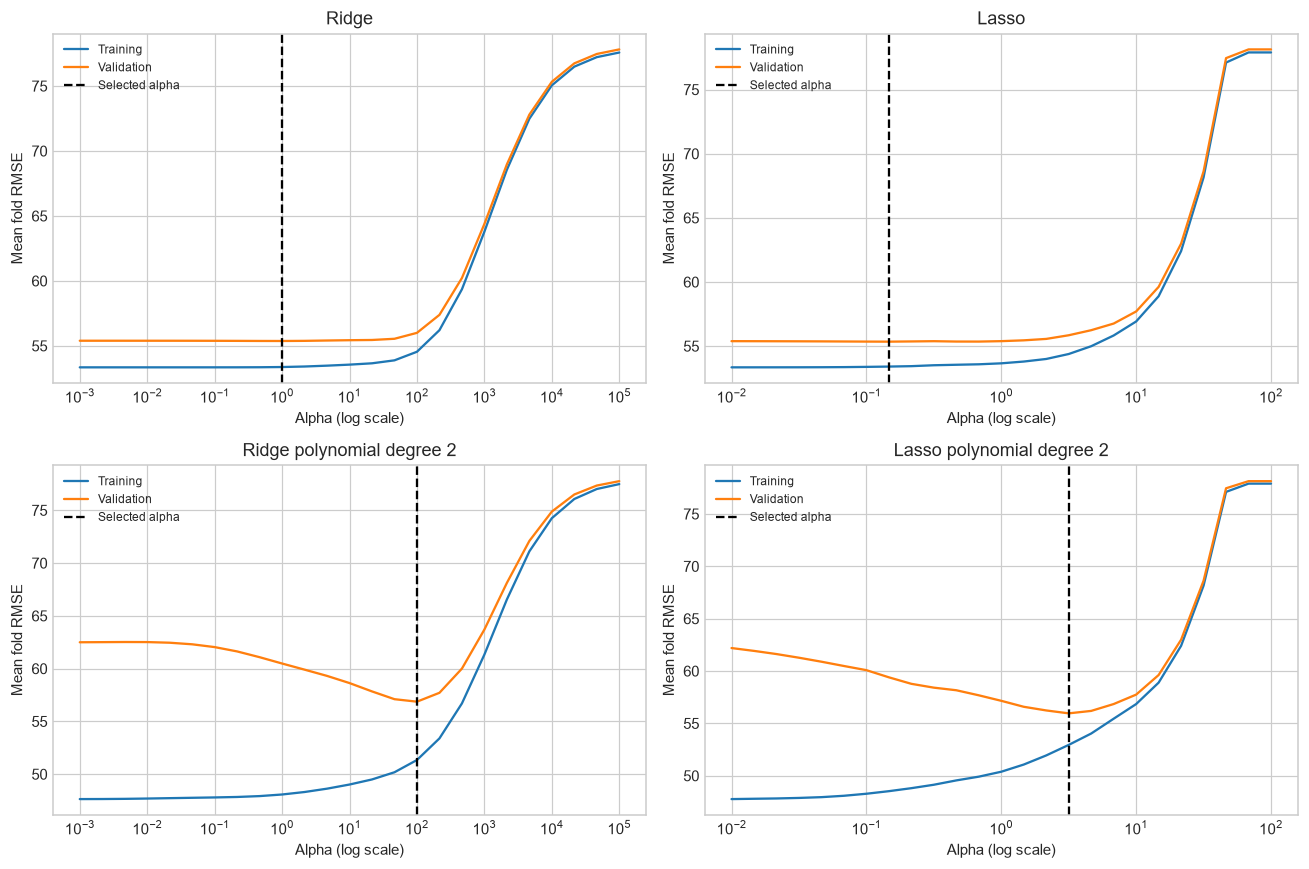

In [7]:
searches = {}
for degree in [1, 2]:
    for kind, estimator, alphas in [
        ('Ridge', Ridge(), np.logspace(-3, 5, 25)),
        ('Lasso', Lasso(max_iter=100000, tol=1e-4), np.logspace(-2, 2, 25))
    ]:
        name = kind if degree == 1 else f'{kind} polynomial degree 2'
        pipe = (Pipeline([('scale', StandardScaler()), ('reg', estimator)])
                if degree == 1 else polynomial_pipeline(degree, estimator))
        # GridSearchCV refits the best setting on all training observations.
        search = GridSearchCV(pipe, {'reg__alpha': alphas}, cv=cv,
                              scoring='neg_root_mean_squared_error', n_jobs=1,
                              return_train_score=True, error_score='raise')
        search.fit(X_train, y_train)
        searches[name] = search
        display(evaluate(name, search.best_estimator_, cv_rmse=-search.best_score_))
        print(f'{name}: selected alpha = {search.best_params_["reg__alpha"]:.5g}')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, search) in zip(axes.flat, searches.items()):
    values = search.cv_results_
    alpha = np.asarray(values['param_reg__alpha'], dtype=float)
    ax.semilogx(alpha, -values['mean_train_score'], label='Training')
    ax.semilogx(alpha, -values['mean_test_score'], label='Validation')
    ax.axvline(search.best_params_['reg__alpha'], color='black', ls='--', label='Selected alpha')
    ax.set(title=name, xlabel='Alpha (log scale)', ylabel='Mean fold RMSE')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / 'alpha_effects.png')
plt.show()

,Multiple linear,Ridge,Lasso
age,1.754,1.807,1.692
sex,-11.512,-11.448,-11.193
bmi,25.607,25.733,25.912
bp,16.829,16.734,16.591
s1,-44.449,-34.672,-27.014
s2,24.641,17.053,11.208
s3,7.677,3.370,-0.000
s4,13.139,11.764,10.400
s5,35.161,31.378,28.653
s6,2.351,2.458,2.393


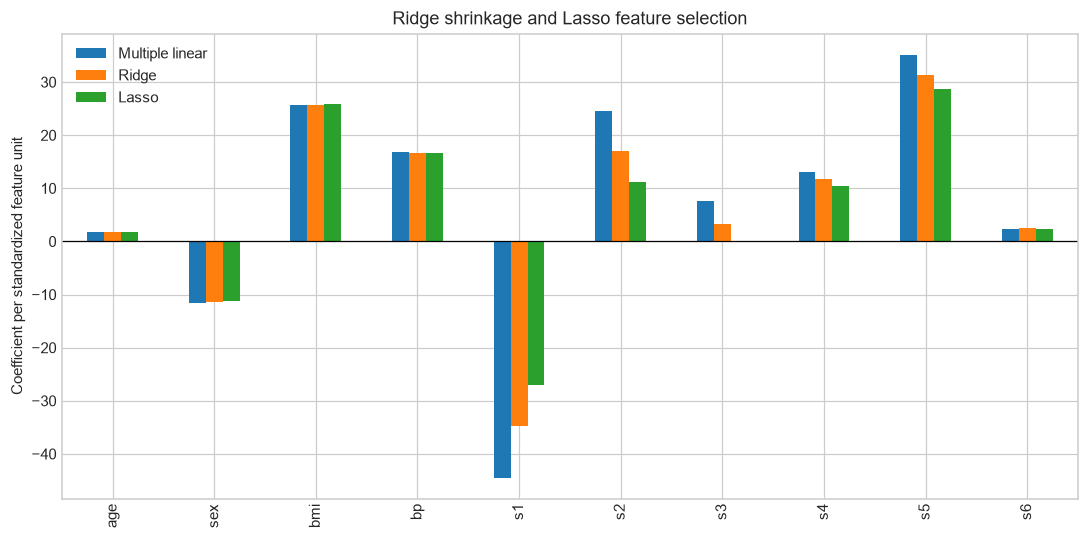

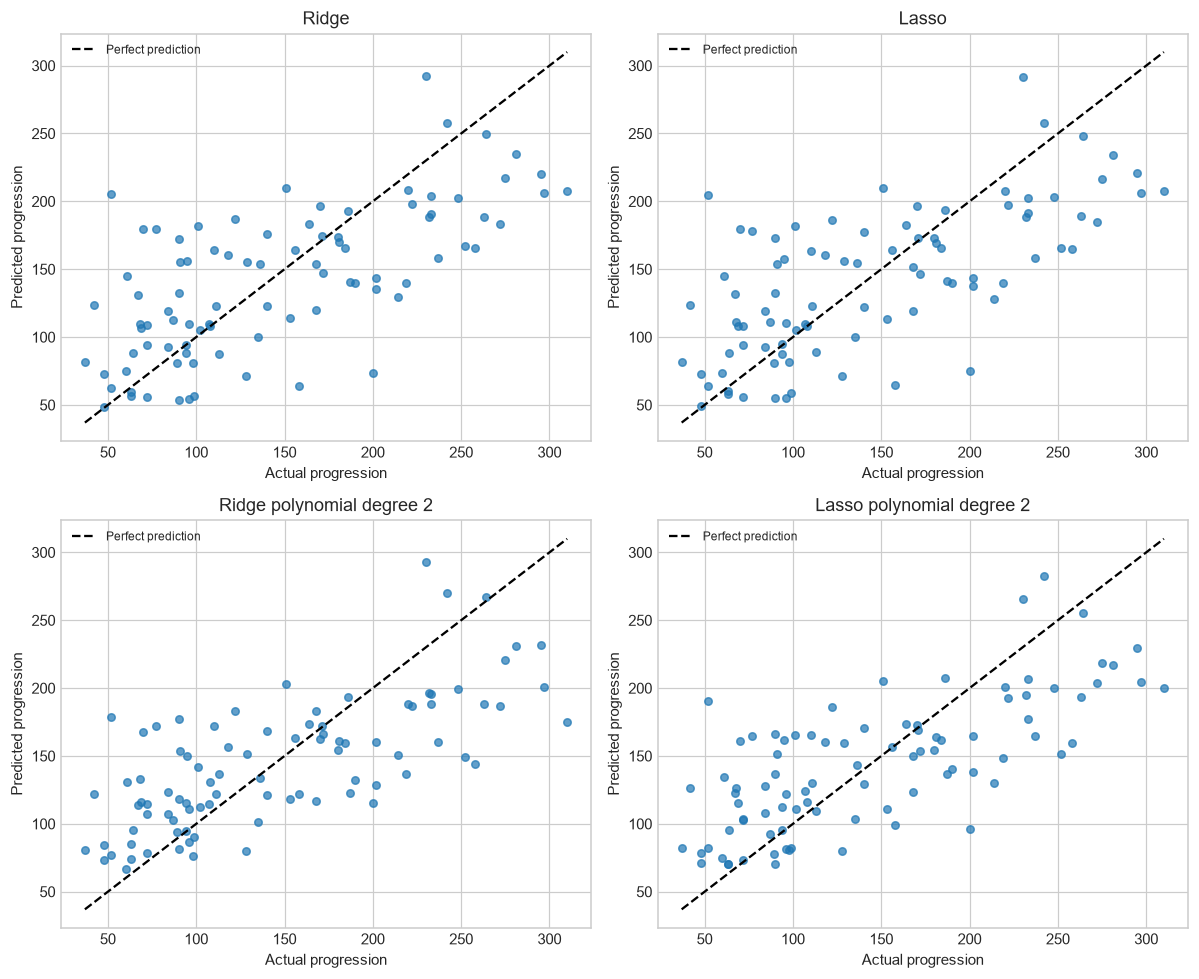

In [8]:
# Compare coefficients on the same standardized original-feature basis.
coefficients = pd.DataFrame({name: models[name].named_steps['reg'].coef_
                             for name in ['Multiple linear', 'Ridge', 'Lasso']}, index=X.columns)
display(coefficients.round(3))
coefficients.plot.bar(figsize=(10, 5))
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Coefficient per standardized feature unit')
plt.title('Ridge shrinkage and Lasso feature selection')
plt.tight_layout()
plt.savefig(OUT / 'coefficients.png')
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flat, searches):
    actual_plot(ax, name)
plt.tight_layout()
plt.savefig(OUT / 'regularized_predictions.png')
plt.show()

## Step 6: Model comparison and analysis
The table reports held-out MAE, MSE, RMSE, and R² alongside training and CV RMSE.
The CV column is the mean fold RMSE, not the RMSE pooled across folds. Fold SD in
the degree experiment describes variation across folds, not a confidence interval.

,MAE,MSE,RMSE,R2,Train RMSE,CV RMSE
Model,,,,,,
Lasso polynomial degree 2,41.269,2569.712,50.692,0.515,53.504,55.958
Ridge polynomial degree 2,41.471,2649.612,51.474,0.500,51.650,56.870
Lasso,42.815,2882.154,53.686,0.456,53.611,55.349
Ridge,42.812,2892.015,53.777,0.454,53.575,55.374
Multiple linear,42.794,2900.194,53.853,0.453,53.559,55.395
Polynomial degree 2,43.582,3096.028,55.642,0.416,48.920,62.505
Simple linear (BMI),52.260,4061.826,63.732,0.233,62.082,62.500
Mean baseline,64.006,5361.533,73.222,-0.012,77.951,NaN
Polynomial degree 3,161.212,77860.008,279.034,-13.696,27.379,1394.877


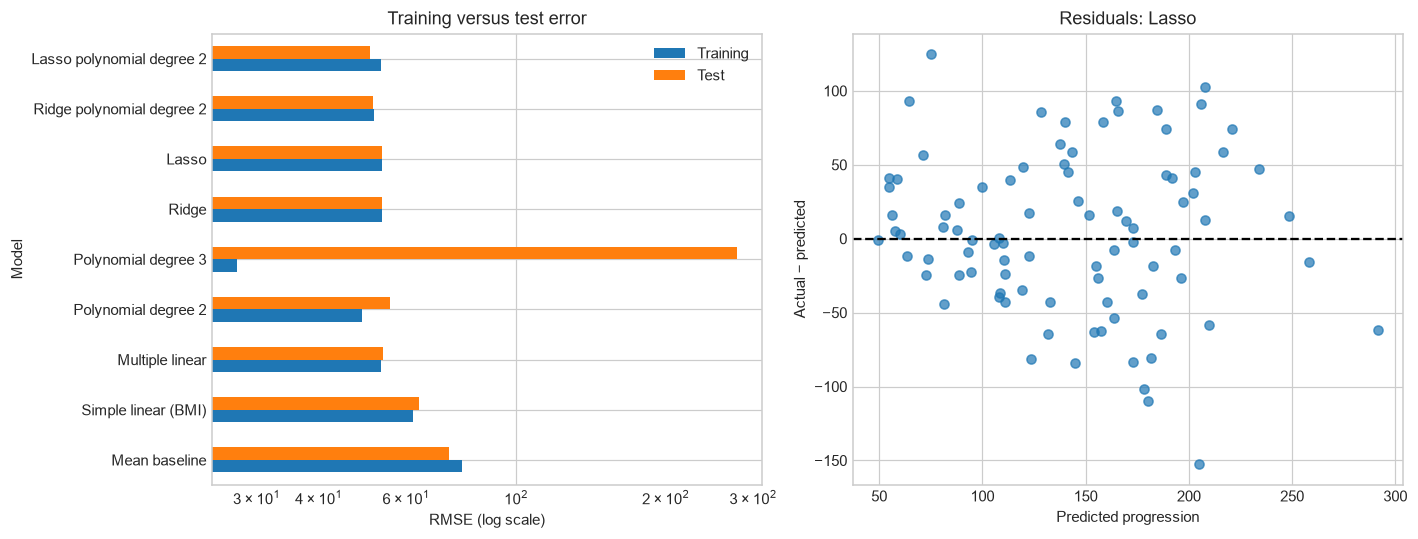

592

In [9]:
results = pd.DataFrame(rows).set_index('Model')
display(results.sort_values('RMSE').round(3))
results.to_csv(OUT / 'model_comparison.csv')
degree_results.to_csv(OUT / 'polynomial_degrees.csv')
coefficients.to_csv(OUT / 'coefficients.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
results[['Train RMSE', 'RMSE']].plot.barh(ax=axes[0], logx=True)
axes[0].set(xlabel='RMSE (log scale)', title='Training versus test error')
axes[0].legend(['Training', 'Test'])
# Choose the model family by training CV, not by the test ranking.
recommended = results['CV RMSE'].idxmin()
residuals = y_test - predictions[recommended]
axes[1].scatter(predictions[recommended], residuals, alpha=0.7)
axes[1].axhline(0, color='black', ls='--')
axes[1].set(xlabel='Predicted progression', ylabel='Actual − predicted',
            title=f'Residuals: {recommended}')
plt.tight_layout()
plt.savefig(OUT / 'model_comparison.png', bbox_inches='tight')
plt.show()

# Save compact numerical evidence for the accompanying written summary.
summary = {'recommended': recommended, 'test_best': results['RMSE'].idxmin(),
           'alphas': {n: float(s.best_params_['reg__alpha']) for n, s in searches.items()},
           'lasso_zero_count': int(np.sum(np.isclose(coefficients['Lasso'], 0))),
           'correlations': corr['target'].drop('target').to_dict()}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2))

### Findings
1. **Simple versus multiple regression:** BMI alone gives test RMSE **63.73** and R²
   **0.233**, improving on the training-mean baseline (RMSE **73.22**). Using all 10
   predictors reduces RMSE to **53.85**, with R² **0.453**. The single-feature model
   misses useful information; its similar training and validation errors suggest limited
   capacity rather than a large overfitting problem.
2. **Polynomial complexity:** Degree 2 reduces training RMSE from **53.56** to **48.92**,
   but raises CV RMSE from **55.39** to **62.50** and test RMSE to **55.64**. Degree 3
   drives training RMSE down to **27.38**, while CV RMSE reaches **1394.88** and test
   RMSE **279.03** (R² **−13.696**). This is severe overfitting and instability in a
   large, correlated polynomial design. Additional flexibility does not guarantee better
   predictions. Among the unregularized degrees, CV prefers degree 1.
3. **Regularization:** On the original predictors, Ridge (alpha **1**) and Lasso
   (alpha **0.14678**) give test RMSE **53.78** and **53.69**. Their gains over ordinary
   multiple regression are small. Lasso sets **1 of 10** coefficients to zero. On the
   degree-2 expansion, Ridge (alpha **100**) reduces test RMSE to **51.47**, and Lasso
   (alpha **3.16228**) reduces it to **50.69**. Both improve on unregularized degree 2;
   Lasso polynomial also has the lowest test MAE (**41.27**) and MSE (**2569.71**).
   The alpha curves illustrate the balance between insufficient shrinkage and excessive
   shrinkage; larger alpha is not automatically better.
4. **Model choice:** Original-feature Lasso has the lowest training CV RMSE (**55.35**),
   narrowly ahead of Ridge (**55.37**) and multiple regression (**55.39**), so it is the
   CV-based recommendation. Polynomial Lasso has the best observed test result
   (R² **0.515**), but its CV RMSE is **55.96**. The held-out ranking is descriptive,
   not a reason to retune on the test set. Small differences among linear models do not
   establish meaningful superiority without further validation.
5. **Dataset insights:** In training data, BMI and `s5` have positive target correlations
   of approximately **0.605** and **0.552**, while `s3` has correlation **−0.384**.
   The correlation heatmap also shows dependence among serum predictors. Combining
   measurements improves prediction, yet substantial variation remains unexplained.
   A weak marginal correlation does not prove that a feature is useless conditionally.

### Challenges and decisions
The main challenges were avoiding preprocessing leakage, comparing models fairly, and
controlling the growth of polynomial terms. A single reproducible split, pipeline-based
scaling, and training-only CV address these issues. Degrees were limited to 1–3 because
degree 3 already creates 285 columns from only 353 training observations. The original
raw dataset values were used so scaling is estimated only on training folds. Lasso's
iteration limit was increased, and convergence warnings were treated as errors during
execution. No missing values or duplicate full rows were found, so no imputation or
row deletion was applied.


## Limitations and reproducibility
There are only 442 observations, and results depend on the chosen split. CV guides
tuning, but its winning score can be optimistic after searching many settings. A single
test set is not enough to establish statistical superiority. Correlated predictors and
redundant polynomial columns complicate coefficient interpretation. Predictions do not
establish causation or clinical usefulness. No missing-value imputation or outlier removal
was needed; extreme observations were retained because there was no evidence of data errors.

Run all cells in order with the packages in `requirements.txt`. The dataset ships with
scikit-learn, so no external dataset download or private data is required. Figures and
tables are saved in `results/`, and all notebook outputs are embedded for GitHub viewing.

## References
- [scikit-learn Diabetes dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)
- [scikit-learn linear models guide](https://scikit-learn.org/stable/modules/linear_model.html)
- [Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
- [Lasso documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html)